In [1]:
#导入所有需要的工具
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
from datap import Data
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import xgboost as xgb
import sklearn
sklearn.set_config(display="text")  # 关闭HTML渲染，使用纯文本显示

In [2]:
#设置中文字体，防止画图时中文乱码
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

In [3]:
#关闭optuna日志
optuna.logging.set_verbosity(optuna.logging.ERROR)

In [4]:
data = Data()

In [5]:
features = ['top', 'crown', 'fai', 'material', 'd/2h', 'Sheet']
x = 't'
y = 'knuckle'
data.read('整体缺陷.xlsx', features, x, y)

In [6]:
features = ['top', 'crown', 'fai', 'xita', 'material', 'd/2h', 'Sheet']
x = 't'
y = 'smax'
data.read('局部缺陷1.xlsx', features, x, y)

In [7]:
features = ['top', 'crown', 'fai', 'smax', 'material', 'd/2h', 'Sheet']
x = 't'
y = 'xita'
data.read('局部缺陷2.xlsx', features, x, y)

In [8]:
features = ['top', 'crown', 'fai', 't', 'material', 'd/2h', 'Sheet']
x = 'xita'
y = 'smax'
data.read('局部缺陷3.xlsx', features, x, y)

In [9]:
features = ['t', 'fai', 'xita', 'material', 'Sheet']
x = 'knuckle'
y = 'smax'
data.read('整体+局部.xlsx', features, x, y)

In [10]:
df = data.merge()

In [11]:
#划分特征列与目标列
feature_cols = df.columns.tolist()
feature_cols = [i for i in feature_cols if i != 'buckling']
print(feature_cols)

['top/d', 'crown/d', 'fai', 'material', 'd/2h', 't/d', 'knuckle/d', 'xita', 'smax/d']


In [12]:
X = df[feature_cols]       #特征列（输入）
Y = df['buckling']    #目标列（输出）

In [13]:
#划分训练集（80%）和测试集（20%）
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size = 0.2, random_state = 42
)
print(f"\n训练集大小：{X_train.shape}，测试集大小：{X_test.shape}")


训练集大小：(965, 9)，测试集大小：(242, 9)


In [14]:
def objective(trial):
    # 💡 XGBoost 的专属搜索空间
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 300),
        'max_depth': trial.suggest_int('max_depth', 3, 8),           # XGB 通常深度更浅
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True), # XGB 核心参数
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),     # 随机采样比例
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0), # 列采样比例
        'random_state': 42,
        'n_jobs': -1
    }
    
    # 💡 换成 XGBRegressor
    model = xgb.XGBRegressor(**params)
    
    # 交叉验证
    scores = cross_val_score(model, X_train, Y_train, cv=5, scoring='r2')
    return scores.mean()

In [15]:
#创建study 
study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42)
)

In [16]:
#优化
print("开始自动搜索最优超参数...")
study.optimize(objective, n_trials=100, show_progress_bar=True)

开始自动搜索最优超参数...


  0%|          | 0/100 [00:00<?, ?it/s]

In [17]:
#输出最优结果
print("\n========== 贝叶斯优化结果 ==========")
print(f"最优交叉验证 R²：{study.best_value:.4f}")
print("最优超参数：")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")


========== 贝叶斯优化结果 ==========
最优交叉验证 R²：0.9914
最优超参数：
  n_estimators: 249
  max_depth: 5
  learning_rate: 0.17609416570765407
  subsample: 0.7791842786403177
  colsample_bytree: 0.7391038642686162


In [18]:
#用最优参数训练最终模型 
best_xgb = xgb.XGBRegressor(**study.best_params, random_state=42, n_jobs=-1)
best_xgb.fit(X_train, Y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.7391038642686162, device=None,
             early_stopping_rounds=None, enable_categorical=False,
             eval_metric=None, feature_types=None, feature_weights=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.17609416570765407,
             max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=5, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=249, n_jobs=-1,
             num_parallel_tree=None, ...)

In [19]:
#预测
Y_pred = best_xgb.predict(X_test)

In [22]:
#计算评估指标
r2 = r2_score(Y_test, Y_pred)
rmse = np.sqrt(mean_squared_error(Y_test, Y_pred))
mae = mean_absolute_error(Y_test, Y_pred)

print("\n模型测试集评估结果")
print(f"R²: {r2:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")


模型测试集评估结果
R²: 0.9930
RMSE: 0.0170
MAE: 0.0104


In [23]:
#特征重要性分析
feature_importance = pd.DataFrame({
    '特征': feature_cols, 
    '重要性': best_xgb.feature_importances_
}).sort_values(by = '重要性', ascending = False)

print("\n特征重要性排名")
print(feature_importance.to_string(index = False))


特征重要性排名
       特征      重要性
 material 0.342471
      t/d 0.193414
      fai 0.164022
     d/2h 0.151217
knuckle/d 0.051157
   smax/d 0.033044
  crown/d 0.028768
     xita 0.020101
    top/d 0.015805


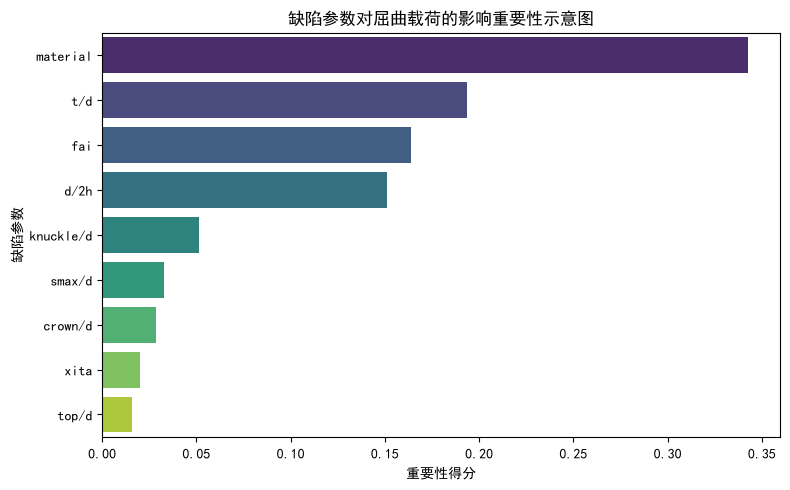

In [24]:
#画特征重要性柱状图
plt.figure(figsize = (8, 5))
sns.barplot(
    x = '重要性', 
    y = '特征', 
    data = feature_importance,
    hue = '特征', 
    palette = 'viridis', 
    legend = False
)
plt.title('缺陷参数对屈曲载荷的影响重要性示意图')
plt.xlabel('重要性得分')
plt.ylabel('缺陷参数')
plt.tight_layout()
plt.show()

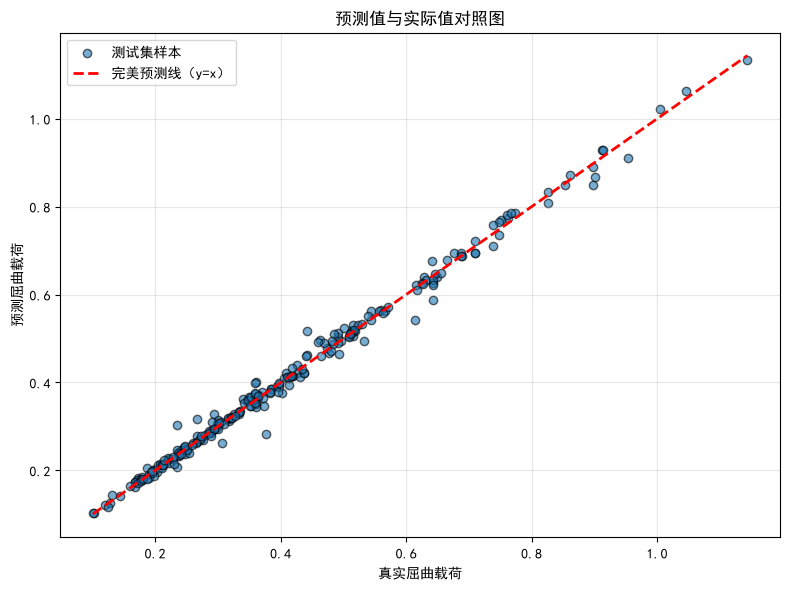

In [25]:
#画预测值与实际值对照图
plt.figure(figsize = (8, 6))
#相关性散点图
plt.scatter(
    Y_test,     #横坐标
    Y_pred,     #纵坐标
    alpha = 0.6, 
    edgecolor = 'k', 
    label = '测试集样本'
)
#画y=x参考线
min_val = min(Y_pred.min(), Y_test.min())
max_val = max(Y_pred.max(), Y_test.max())
plt.plot(
    [min_val, max_val], 
    [min_val, max_val], 
    'r--', 
    lw = 2, 
    label = '完美预测线（y=x）'
)
plt.xlabel('真实屈曲载荷')
plt.ylabel('预测屈曲载荷')
plt.title('预测值与实际值对照图')
plt.legend()
plt.grid(True, alpha = 0.3)
plt.tight_layout()
plt.show()

In [26]:
#保存模型

import joblib
joblib.dump(best_xgb, 'best_model.pkl')
print('模型已保存为best_model.pkl')


模型已保存为best_model.pkl
